# Objetivo

O objetivo deste projeto é desenvolver um modelo de Machine Learning capaz de prever a quantidade de kills (`qtKill`) de um jogador em uma partida de CS, utilizando seu histórico de desempenho em partidas anteriores.

In [1]:
#BIBLIOTECAS_E_IMPORTS

import sys
from pathlib import Path
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ajuste a raiz caso o notebook não esteja na pasta raiz do projeto.
RAIZ_PROJETO = Path.cwd()
if not (RAIZ_PROJETO / "src").exists():
    # Caso o notebook esteja dentro de uma subpasta, procura a raiz acima.
    candidatos = [p for p in Path.cwd().parents if (p / "src").exists()]
    if candidatos:
        RAIZ_PROJETO = candidatos[0]

if str(RAIZ_PROJETO) not in sys.path:
    sys.path.insert(0, str(RAIZ_PROJETO))

# Imports dos módulos do próprio projeto.
from sklearn.neighbors import NearestNeighbors
from src.preprocessing.feature_historico import FEATURE_COLUMNS
from src.data.dataset_final import carregar_dataset_final
from src.preprocessing.separacao_dados import dividir_por_tempo, resumo_separacao, verificar_ordem_temporal

print("Raiz do projeto:", RAIZ_PROJETO)
print("Quantidade de features oficiais:", len(FEATURE_COLUMNS))

Raiz do projeto: D:\Marcus\Projeto-IA3
Quantidade de features oficiais: 25


In [2]:
#CARREGAMENTO_DO_DATASET_FINAL

df = carregar_dataset_final()

print(f"Registros: {len(df):,}")
print(f"Colunas: {len(df.columns)}")
display(df.head())
display(df.info())

Registros: 172,773
Colunas: 29


,idPlayer,idLobbyGame,dtCreatedAt,qtdAnteriores,killsUltimaPartida,nivelAnterior,mediaKills_5,mediaKills_20,mediaKills_hist,mediaDano_5,...,taxaVitorias_20,taxaVitorias_hist,tirosPorKill_5,tirosPorKill_20,tirosPorKill_hist,killsPorRound_5,killsPorRound_20,killsPorRound_hist,desvioKills_20,qtKill
0,2,8,2021-10-12 16:48:09,5,11,2,10.2,10.200000,10.200000,1540.6,...,0.200000,0.200000,27.568627,27.568627,27.568627,0.435897,0.435897,0.435897,3.768289,8
1,2,9,2021-10-17 17:02:08,6,8,2,10.6,9.833333,9.833333,1590.2,...,0.166667,0.166667,28.716981,29.305085,29.305085,0.490741,0.443609,0.443609,3.488075,5
2,2,10,2021-10-17 18:09:18,7,5,2,10.0,9.142857,9.142857,1452.0,...,0.142857,0.142857,26.960000,29.359375,29.359375,0.555556,0.441379,0.441379,3.670993,19
3,2,11,2021-10-17 23:20:21,8,19,2,11.8,10.375000,10.375000,1703.2,...,0.125000,0.125000,23.271186,27.240964,27.240964,0.608247,0.482558,0.482558,4.867898,5
4,2,12,2021-10-18 00:22:34,9,5,1,9.6,9.777778,9.777778,1458.4,...,0.222222,0.222222,25.770833,27.454545,27.454545,0.457143,0.440000,0.440000,4.893306,9


<class 'pandas.DataFrame'>
RangeIndex: 172773 entries, 0 to 172772
Data columns (total 29 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   idPlayer             172773 non-null  int64         
 1   idLobbyGame          172773 non-null  int64         
 2   dtCreatedAt          172773 non-null  datetime64[us]
 3   qtdAnteriores        172773 non-null  int64         
 4   killsUltimaPartida   172773 non-null  int64         
 5   nivelAnterior        172773 non-null  int64         
 6   mediaKills_5         172773 non-null  float64       
 7   mediaKills_20        172773 non-null  float64       
 8   mediaKills_hist      172773 non-null  float64       
 9   mediaDano_5          172773 non-null  float64       
 10  mediaDano_20         172773 non-null  float64       
 11  mediaDano_hist       172773 non-null  float64       
 12  mediaHeadshots_5     172773 non-null  float64       
 13  mediaHeadshots_20    1727

None

In [3]:
#DEFINIÇÃO_DAS_ENTRADAS_E_DO_ALVO

ALVO = "qtKill"
COLUNAS_CONTEXTO = ["idPlayer", "idLobbyGame", "dtCreatedAt"]

# Confere se o dataset contém todas as colunas esperadas.
colunas_necessarias = COLUNAS_CONTEXTO + list(FEATURE_COLUMNS) + [ALVO]
faltantes = [col for col in colunas_necessarias if col not in df.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes no dataset final: {faltantes}")

X = df.loc[:, list(FEATURE_COLUMNS)].copy()
y = df[ALVO].copy()

print("Features utilizadas:")
for coluna in FEATURE_COLUMNS:
    print("-", coluna)

print("\nAlvo:", ALVO)
print("Há valores ausentes nas features?", bool(X.isna().any().any()))
print("Há valores ausentes no alvo?", bool(y.isna().any()))

Features utilizadas:
- qtdAnteriores
- killsUltimaPartida
- nivelAnterior
- mediaKills_5
- mediaKills_20
- mediaKills_hist
- mediaDano_5
- mediaDano_20
- mediaDano_hist
- mediaHeadshots_5
- mediaHeadshots_20
- mediaHeadshots_hist
- mediaRounds_5
- mediaRounds_20
- mediaRounds_hist
- taxaVitorias_5
- taxaVitorias_20
- taxaVitorias_hist
- tirosPorKill_5
- tirosPorKill_20
- tirosPorKill_hist
- killsPorRound_5
- killsPorRound_20
- killsPorRound_hist
- desvioKills_20

Alvo: qtKill
Há valores ausentes nas features? False
Há valores ausentes no alvo? False


In [4]:
#SEPARAÇÃO_TEMPORAL

treino, validacao, teste = dividir_por_tempo(df)

# Verifica que as janelas temporais não se sobrepõem.
verificar_ordem_temporal(treino, validacao, teste)

display(resumo_separacao(treino, validacao, teste))

# Índices preservados pelo split identificam as linhas correspondentes.
X_treino = treino[list(FEATURE_COLUMNS)]
y_treino = treino[ALVO]

X_validacao = validacao[list(FEATURE_COLUMNS)]
y_validacao = validacao[ALVO]

X_teste = teste[list(FEATURE_COLUMNS)]
y_teste = teste[ALVO]

print(f"Treino: {len(X_treino):,} linhas")
print(f"Validação: {len(X_validacao):,} linhas")
print(f"Teste: {len(X_teste):,} linhas")

,Linhas,Porcentagem (%),Primeira data,Última data,Jogadores
Treino,120941,70.0,2021-09-14 19:07:41,2022-01-09 00:05:31,1608
Validação,25916,15.0,2022-01-09 00:06:07,2022-01-26 03:52:44,1549
Teste,25916,15.0,2022-01-26 03:53:43,2022-02-11 13:27:48,1671


Treino: 120,941 linhas
Validação: 25,916 linhas
Teste: 25,916 linhas


In [5]:
#PADRONIZAÇÃO_DAS_FEATURES

scaler = StandardScaler()

X_treino_scaled = scaler.fit_transform(X_treino)
X_validacao_scaled = scaler.transform(X_validacao)
X_teste_scaled = scaler.transform(X_teste)

print("Dimensão do treino padronizado:", X_treino_scaled.shape)
print("Dimensão da validação padronizada:", X_validacao_scaled.shape)
print("Dimensão do teste padronizado:", X_teste_scaled.shape)

Dimensão do treino padronizado: (120941, 25)
Dimensão da validação padronizada: (25916, 25)
Dimensão do teste padronizado: (25916, 25)


# Estratégia

Foi utilizado o algoritmo K-Nearest Neighbors (KNN), que realiza previsões com base nos jogadores com características mais semelhantes.

O conjunto de dados foi dividido temporalmente em treino (70%), validação (15%) e teste (15%), respeitando a ordem cronológica das partidas.

Foram testadas diferentes quantidades de vizinhos (K) e métricas de distância. O melhor modelo foi escolhido com base no menor MAE na validação, sendo utilizado posteriormente no conjunto de teste.

In [6]:
#BUSCA_DE_HIPERPARÂMETROS_NA_VALIDAÇÃO

VALORES_K = [3, 5, 7, 9, 11, 15, 20, 30, 40, 50, 100, 200, 300]

DISTANCIAS = ["euclidean", "manhattan", "chebyshev"]

# Converte as kills do treino para um array NumPy
y_treino_np = y_treino.to_numpy()

# Lista que armazenará os resultados de cada combinação
resultados_validacao = []

# Testa cada métrica de distância
for distancia in DISTANCIAS:

    # Busca os 300 vizinhos mais próximos de cada partida
    busca = NearestNeighbors(
        n_neighbors=max(VALORES_K),
        metric=distancia,
        n_jobs=-1
    )

    # Ajusta a busca utilizando os dados de treino
    busca.fit(X_treino_scaled)

    # Encontra os vizinhos mais próximos das partidas de validação
    _, vizinhos = busca.kneighbors(X_validacao_scaled)

    # Recupera a quantidade de kills dos vizinhos encontrados
    kills_vizinhos = y_treino_np[vizinhos]

    # Testa cada valor de K utilizando os vizinhos já encontrados
    for k in VALORES_K:

        # Calcula a média das kills dos K vizinhos mais próximos
        previsoes = kills_vizinhos[:, :k].mean(axis=1)

        # Calcula o erro médio absoluto (MAE)
        mae = mean_absolute_error(
            y_validacao,
            previsoes
        )

        # Armazena os resultados
        resultados_validacao.append({
            "K": k,
            "Distância": distancia,
            "MAE validação": mae
        })

# Transforma os resultados em uma tabela
resultados_validacao = pd.DataFrame(resultados_validacao)

# Organiza do menor MAE para o maior
resultados_validacao = resultados_validacao.sort_values(
    "MAE validação",
    ascending=True
).reset_index(drop=True)

# Exibe as 15 melhores combinações
display(resultados_validacao.head(15))


,K,Distância,MAE validação
0,300,manhattan,5.377264
1,200,manhattan,5.380677
2,300,euclidean,5.381383
3,200,euclidean,5.386161
4,100,manhattan,5.393125
5,100,euclidean,5.401084
6,200,chebyshev,5.422571
7,50,manhattan,5.423496
8,300,chebyshev,5.425097
9,100,chebyshev,5.427794


In [7]:
#SELEÇÃO_DO_MELHOR_MODELO

melhor_resultado = resultados_validacao.iloc[0]
melhor_k = int(melhor_resultado["K"])
melhor_distancia = melhor_resultado["Distância"]
melhor_mae_validacao = float(melhor_resultado["MAE validação"])

print(f"Melhor K: {melhor_k}")
print(f"Melhor distância: {melhor_distancia}")
print(f"MAE na validação: {melhor_mae_validacao:.4f}")

Melhor K: 300
Melhor distância: manhattan
MAE na validação: 5.3773


In [9]:
#AVALIAÇÃO_FINAL_NO_CONJUNTO_DE_TESTE

modelo_final = KNeighborsRegressor(
    n_neighbors=melhor_k,
    metric=melhor_distancia,
    weights="uniform",
    n_jobs=-1
)
modelo_final.fit(X_treino_scaled, y_treino)

previsoes_teste = modelo_final.predict(X_teste_scaled)

mae_teste = mean_absolute_error(y_teste, previsoes_teste)
rmse_teste = np.sqrt(mean_squared_error(y_teste, previsoes_teste))
r2_teste = r2_score(y_teste, previsoes_teste)

print(f"MAE no teste:  {mae_teste:.4f}")
print(f"RMSE no teste: {rmse_teste:.4f}")
print(f"R² no teste:   {r2_teste:.4f}")

MAE no teste:  5.3695
RMSE no teste: 6.9737
R² no teste:   0.1429


# Resultados

A melhor configuração encontrada foi:

- **Algoritmo:** KNN
- **Quantidade de vizinhos (K):** 300
- **Distância:** Manhattan
- **MAE na validação:** 5,377
- **MAE no teste:** 5,370

O resultado indica que o modelo apresenta um erro absoluto médio de aproximadamente 5,37 kills por previsão.

In [10]:
#COMPARAÇÃO_COM_O_BASELINE

MAE_BASELINE = mean_absolute_error(
    y_teste,
    teste["mediaKills_hist"]
)

comparacao = pd.DataFrame({
    "Modelo": ["Baseline", "KNN"],
    "MAE teste": [MAE_BASELINE, mae_teste]
})
comparacao["Diferença para baseline"] = comparacao["MAE teste"] - MAE_BASELINE

display(comparacao)

melhoria_absoluta = MAE_BASELINE - mae_teste
melhoria_percentual = (melhoria_absoluta / MAE_BASELINE) * 100

print(f"Redução absoluta do MAE: {melhoria_absoluta:.4f}")
print(f"Redução percentual do MAE: {melhoria_percentual:.2f}%")

,Modelo,MAE teste,Diferença para baseline
0,Baseline,5.412317,0.000000
1,KNN,5.369530,-0.042787


Redução absoluta do MAE: 0.0428
Redução percentual do MAE: 0.79%


# Comparação com a Baseline

Para avaliar se o KNN realmente trouxe melhorias, seus resultados foram comparados com uma baseline que utiliza a média histórica de kills do jogador (`mediaKills_hist`) como previsão.

- **MAE da Baseline:** aproximadamente 5,412
- **MAE do KNN:** aproximadamente 5,370
- **Melhoria:** aproximadamente 0,8%

O KNN apresentou um erro ligeiramente menor que a baseline. Embora a melhoria seja pequena, demonstra que o modelo conseguiu aproveitar as características históricas dos jogadores para produzir previsões um pouco mais precisas.

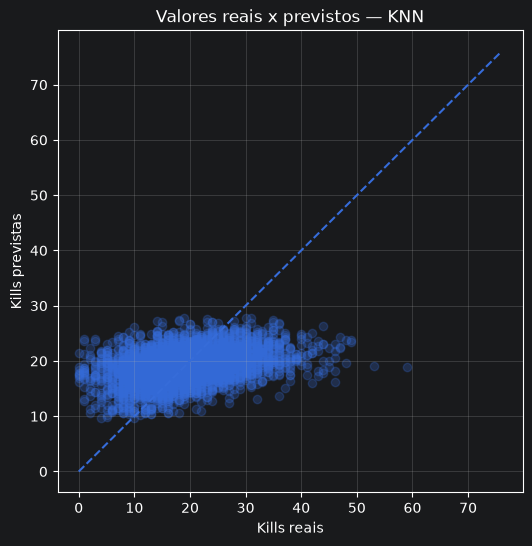

In [11]:
#VISUALIZAÇÃO_DOS_RESULTADOS

quantidade_amostra = min(5000, len(y_teste))
amostra = np.random.default_rng(42).choice(len(y_teste), size=quantidade_amostra, replace=False)

plt.figure(figsize=(6, 6))
plt.scatter(
    y_teste.iloc[amostra],
    previsoes_teste[amostra],
    alpha=0.25
)
limite = max(float(y_teste.max()), float(np.max(previsoes_teste)))
plt.plot([0, limite], [0, limite], linestyle="--")
plt.xlabel("Kills reais")
plt.ylabel("Kills previstas")
plt.title("Valores reais x previstos — KNN")
plt.grid(alpha=0.3)
plt.show()

In [12]:
#ANÁLISE_DOS_ERROS

analise_erros = pd.DataFrame({
    "real": y_teste.to_numpy(),
    "previsto": previsoes_teste
})
analise_erros["erro_absoluto"] = (analise_erros["real"] - analise_erros["previsto"]).abs()

analise_erros["faixa_kills"] = pd.cut(
    analise_erros["real"],
    bins=[-0.001, 5, 10, 15, 20, 30, np.inf],
    labels=["0–5", "6–10", "11–15", "16–20", "21–30", "31+"]
)

display(
    analise_erros.groupby("faixa_kills", observed=False)
    .agg(
        Quantidade=("real", "size"),
        MAE=("erro_absoluto", "mean"),
        Média_real=("real", "mean"),
        Média_prevista=("previsto", "mean")
    )
    .round(3)
)

,Quantidade,MAE,Média_real,Média_prevista
faixa_kills,,,,
0–5,657,13.757,3.160,16.917
6–10,2304,8.925,8.490,17.413
11–15,5391,5.077,13.243,18.199
16–20,7219,2.224,18.018,18.950
21–30,8615,4.759,24.427,19.876
31+,1730,14.525,35.526,21.001


In [13]:
#SALVAMENTO_DOS_RESULTADOS

PASTA_SAIDA = RAIZ_PROJETO / "results" / "metrics"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

resultados_validacao.to_csv(
    PASTA_SAIDA / "resultados_validacao_knn.csv",
    index=False
)
comparacao.to_csv(
    PASTA_SAIDA / "comparacao_baseline_knn.csv",
    index=False
)

metricas_finais = pd.DataFrame([{
    "K_escolhido": melhor_k,
    "distancia": melhor_distancia,
    "MAE_validacao": melhor_mae_validacao,
    "MAE_teste": mae_teste,
    "RMSE_teste": rmse_teste,
    "R2_teste": r2_teste,
    "MAE_baseline": MAE_BASELINE
}])
metricas_finais.to_csv(PASTA_SAIDA / "metricas_finais_knn.csv", index=False)

print("Arquivos salvos em:", PASTA_SAIDA)

Arquivos salvos em: D:\Marcus\Projeto-IA3\results\metrics
